%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


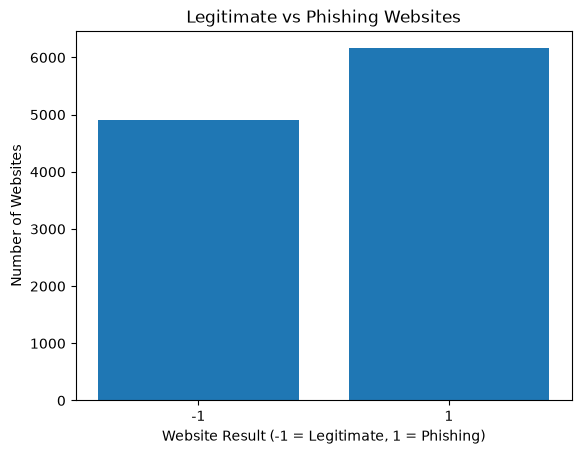

In [7]:
# Imports 
%pylab inline
import pandas as pd
import matplotlib.pyplot as plt

# Reads the dataset
ph = pd.read_csv('../dataset1.csv')

# Displays the first 5 rows of the dataset
result_counts = ph['Result'].value_counts().sort_index()

# Creates a bar chart to visualize the number of legitimate and phishing websites
fig, ax = plt.subplots()

# displays the bar chart
ax.bar(result_counts.index.astype(str), result_counts.values)

# sets text for the x-axis, y-axis, and title of the chart
ax.set_xlabel('Website Result (-1 = Legitimate, 1 = Phishing)')
ax.set_ylabel('Number of Websites')
ax.set_title('Legitimate vs Phishing Websites')

# shows the bar chart
plt.show()


In [8]:
# Imports 
%pylab inline
import pandas as pd
import matplotlib.pyplot as plt

# Reads the dataset
ph = pd.read_csv('../dataset1.csv')

# Displays the first 5 rows of the dataset
ph.head()

# Displays the shape of the dataset
ph.shape 

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


(11055, 32)

In [9]:
# Displays the column names of the dataset
ph.columns

Index(['index ', 'having_IPhaving_IP_Address ', 'URLURL_Length ',
       'Shortining_Service ', 'having_At_Symbol ', 'double_slash_redirecting ',
       'Prefix_Suffix ', 'having_Sub_Domain ', 'SSLfinal_State ',
       'Domain_registeration_length ', 'Favicon ', 'port ', 'HTTPS_token ',
       'Request_URL ', 'URL_of_Anchor ', 'Links_in_tags ', 'SFH ',
       'Submitting_to_email ', 'Abnormal_URL ', 'Redirect ', 'on_mouseover ',
       'RightClick ', 'popUpWidnow ', 'Iframe ', 'age_of_domain ',
       'DNSRecord ', 'web_traffic ', 'Page_Rank ', 'Google_Index ',
       'Links_pointing_to_page ', 'Statistical_report ', 'Result'],
      dtype='str')

In [10]:
ph['Result'].head()

0   -1
1   -1
2   -1
3   -1
4    1
Name: Result, dtype: int64

In [11]:
# Displays the first 5 rows of the 'SSLfinal_State' column
ph.columns = ph.columns.str.strip()
ph['SSLfinal_State'].head()

0   -1
1    1
2   -1
3   -1
4    1
Name: SSLfinal_State, dtype: int64

In [12]:
# Displays the value counts of the 'SSLfinal_State' column
ph['SSLfinal_State'].value_counts()

SSLfinal_State
 1    6331
-1    3557
 0    1167
Name: count, dtype: int64

<Axes: xlabel='SSLfinal_State'>

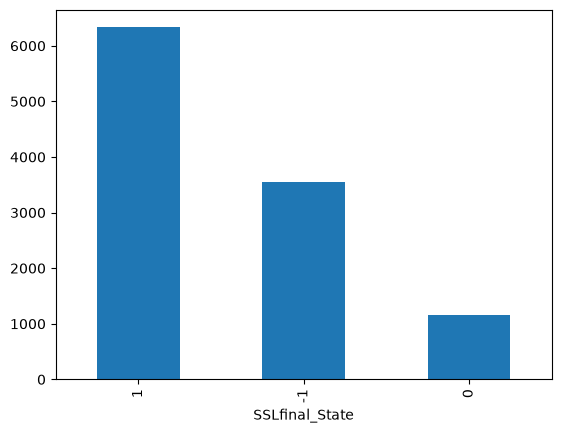

In [13]:
# Creates a bar chart to visualize the distribution of SSLfinal_State values
ph['SSLfinal_State'].value_counts().plot(kind='bar')

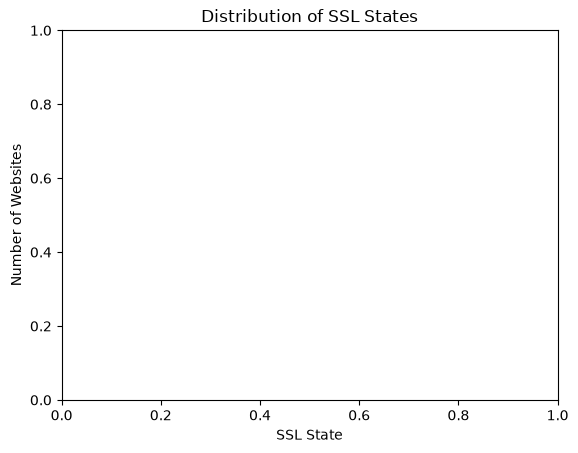

In [14]:
import matplotlib.pyplot as plt

# Creates a bar chart to visualize the distribution of SSLfinal_State values
plt.title('Distribution of SSL States')
plt.xlabel('SSL State')
plt.ylabel('Number of Websites')
plt.show()

In [15]:
# Displays the value counts of the 'Result' column
ph['Result'].value_counts()

Result
 1    6157
-1    4898
Name: count, dtype: int64

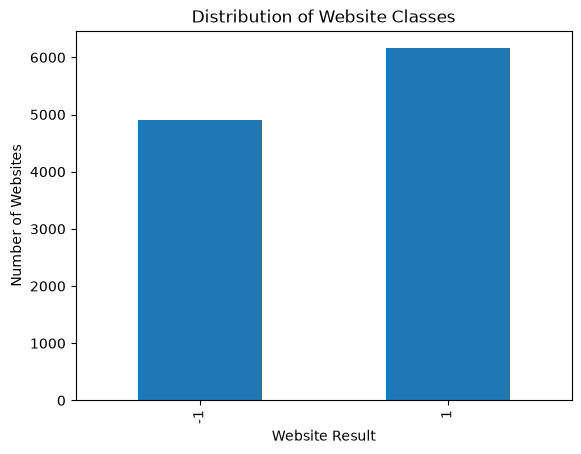

In [16]:
# Creates a bar chart to visualize the distribution of website classes
ph['Result'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribution of Website Classes')
plt.xlabel('Website Result')
plt.ylabel('Number of Websites')
plt.show()

In [17]:
# Creates a cross-tabulation of SSLfinal_State and Result
pd.crosstab(ph['SSLfinal_State'], ph['Result'])

Result,-1,1
SSLfinal_State,,
-1,3051,506
0,1146,21
1,701,5630


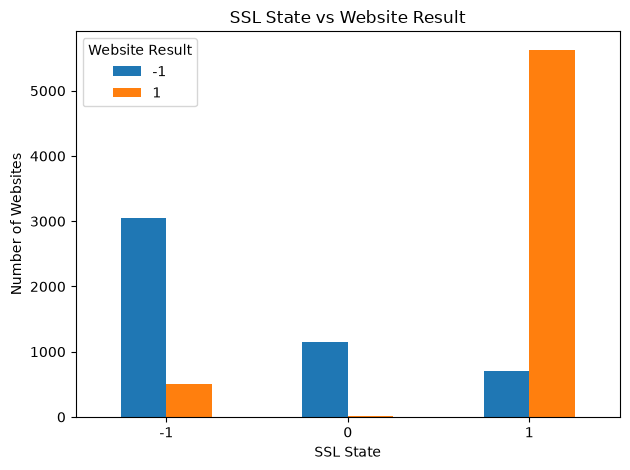

In [18]:
# Creates a bar chart to visualize the relationship between SSLfinal_State and Result
pd.crosstab(
    ph['SSLfinal_State'],
    ph['Result']
).plot(kind='bar')

# Sets the title, x-axis label, y-axis label, and legend for the bar chart
plt.title('SSL State vs Website Result')
plt.xlabel('SSL State')
plt.ylabel('Number of Websites')
plt.xticks(rotation=0)
plt.legend(title='Website Result')
plt.tight_layout()
plt.show()

In [19]:
# Displays the shape of the dataset
print(ph.shape)
print(ph.columns.tolist())


(11055, 32)
['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']


In [20]:
# Separates the features and target variable
X = ph.drop(columns=['Result', 'index'])
y = ph['Result']

In [21]:
# Displays the shape of the features and target variable
print(X.shape)
print(y.shape)

(11055, 30)
(11055,)


In [22]:
# Splits the dataset into training and testing sets
from sklearn.model_selection import train_test_split

In [23]:
# Splits the dataset into training and testing sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [24]:
# Displays the shape of the training and testing sets
print(X_train.shape)
print(X_test.shape)

(8844, 30)
(2211, 30)


In [25]:
# Imports the LogisticRegression class from the sklearn.linear_model module
from sklearn.linear_model import LogisticRegression

In [26]:
# Creates an instance of the LogisticRegression model with a maximum of 1000 iterations
model = LogisticRegression(max_iter=1000)

In [27]:
# Fits the LogisticRegression model to the training data
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [29]:
# Makes predictions on the testing set
y_pred = model.predict(X_test)

In [30]:
# Displays the first 10 predictions made by the model
print(y_pred[:10])

[-1 -1  1 -1 -1  1  1  1  1  1]


In [31]:
# Displays the first 10 actual values of the target variable in the testing set
print(y_test[:10].to_list())

[-1, -1, 1, -1, -1, 1, 1, 1, 1, -1]


In [32]:
# Calculates the accuracy of the model's predictions
from sklearn.metrics import accuracy_score

In [33]:
# Calculates the accuracy of the model's predictions
accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", accuracy * 100, "%")

Model accuracy: 92.8991406603347 %


In [34]:
from sklearn.metrics import confusion_matrix

# Calculates the confusion matrix to evaluate the performance of the model
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 884   96]
 [  61 1170]]


In [35]:
from sklearn.metrics import classification_report

# Generates a classification report to evaluate the performance of the model
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          -1       0.94      0.90      0.92       980
           1       0.92      0.95      0.94      1231

    accuracy                           0.93      2211
   macro avg       0.93      0.93      0.93      2211
weighted avg       0.93      0.93      0.93      2211



In [36]:
# Displays the value counts of the 'Result' column
print(ph['Result'].value_counts())

Result
 1    6157
-1    4898
Name: count, dtype: int64


In [37]:
from sklearn.tree import DecisionTreeClassifier

In [38]:
# Creates an instance of the DecisionTreeClassifier model with a random state of 42
tree_model = DecisionTreeClassifier(random_state=42)

# Fits the DecisionTreeClassifier model to the training data
tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [39]:
# Makes predictions on the testing set using the DecisionTreeClassifier model
tree_pred = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)
print("Decision Tree accuracy:", tree_accuracy * 100, "%")

Decision Tree accuracy: 97.10538218000904 %


In [40]:
import pandas as pd

# Reads the dataset
ph = pd.read_csv('../dataset1.csv')
# Removes any leading or trailing whitespace from the column names
ph.columns = ph.columns.str.strip()
# Displays the shape of the dataset
print(ph.shape)
# Separates the features and target variable
X = ph.drop(columns=['Result', 'index'])
y = ph['Result']

# Displays the shape of the features and target variable
print(X.shape)
print(y.shape)

from sklearn.model_selection import train_test_split

# Splits the dataset into training and testing sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

(11055, 32)
(11055, 30)
(11055,)


In [41]:
from sklearn.metrics import classification_report

# Generates a classification report to evaluate the performance of the DecisionTreeClassifier model
print(classification_report(y_test, tree_pred))

              precision    recall  f1-score   support

          -1       0.97      0.96      0.97       980
           1       0.97      0.98      0.97      1231

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



In [42]:
from sklearn.ensemble import RandomForestClassifier

In [43]:
# Creates an instance of the RandomForestClassifier model with 100 estimators and a random state of 42
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [44]:
# Makes predictions on the testing set using the RandomForestClassifier model
forest_pred = forest_model.predict(X_test)

# Calculates the accuracy of the RandomForestClassifier model's predictions
forest_accuracy = accuracy_score(y_test, forest_pred)

# Displays the accuracy of the RandomForestClassifier model's predictions
print("Random Forest accuracy:", forest_accuracy * 100, "%")

Random Forest accuracy: 97.42198100407056 %


In [45]:
# Generates a classification report to evaluate the performance of the RandomForestClassifier model
print(classification_report(y_test, forest_pred))

              precision    recall  f1-score   support

          -1       0.98      0.96      0.97       980
           1       0.97      0.98      0.98      1231

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



In [46]:
# Creates a DataFrame to compare the accuracy of the three models
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, forest_pred)
    ]
})

# Converts the accuracy values to percentages
results['Accuracy'] = results['Accuracy'] * 100

# Displays the comparison of model accuracies
print(results)

                 Model   Accuracy
0  Logistic Regression  92.899141
1        Decision Tree  97.105382
2        Random Forest  97.421981


In [47]:
# Calculates the training accuracy for each model
log_train_pred = model.predict(X_train)
tree_train_pred = tree_model.predict(X_train)
forest_train_pred = forest_model.predict(X_train)

# Displays the training accuracy for each model
print("Logistic Regression training accuracy:",
      accuracy_score(y_train, log_train_pred) * 100)

print("Decision Tree training accuracy:",
      accuracy_score(y_train, tree_train_pred) * 100)

print("Random Forest training accuracy:",
      accuracy_score(y_train, forest_train_pred) * 100)

Logistic Regression training accuracy: 92.76345545002262
Decision Tree training accuracy: 99.01628222523745
Random Forest training accuracy: 99.01628222523745


In [48]:
# Creates a smaller DecisionTreeClassifier model with a maximum depth of 10 and a random state of 42
small_tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

# Fits the smaller DecisionTreeClassifier model to the training data
small_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [49]:
# Makes predictions on the training and testing sets using the smaller DecisionTreeClassifier model
small_tree_train = small_tree.predict(X_train)
small_tree_test = small_tree.predict(X_test)

# Displays the training and testing accuracy for the smaller DecisionTreeClassifier model
print("Training accuracy:",
      accuracy_score(y_train, small_tree_train) * 100)

print("Test accuracy:",
      accuracy_score(y_test, small_tree_test) * 100)

Training accuracy: 95.95205789235641
Test accuracy: 94.79873360470376


In [50]:
# Generates a classification report to evaluate the performance of the RandomForestClassifier model
print(classification_report(y_test, forest_pred))

              precision    recall  f1-score   support

          -1       0.98      0.96      0.97       980
           1       0.97      0.98      0.98      1231

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



In [51]:
# Creates a DataFrame to compare the accuracy and phishing recall of the three models
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, tree_pred) * 100,
        accuracy_score(y_test, forest_pred) * 100
    ],
    'Phishing Recall': [
        classification_report(
            y_test, y_pred, output_dict=True
        )['-1']['recall'] * 100,
        classification_report(
            y_test, tree_pred, output_dict=True
        )['-1']['recall'] * 100,
        classification_report(
            y_test, forest_pred, output_dict=True
        )['-1']['recall'] * 100
    ]
})

print(results.round(2))

                 Model  Accuracy  Phishing Recall
0  Logistic Regression     92.90            90.20
1        Decision Tree     97.11            96.22
2        Random Forest     97.42            96.12


In [52]:
from sklearn.model_selection import cross_val_score

# Performs cross-validation on the RandomForestClassifier model to evaluate its performance
forest_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Performs cross-validation on the RandomForestClassifier model using 5-fold cross-validation and accuracy as the scoring metric
scores = cross_val_score(
    forest_cv, X, y, cv=5, scoring='accuracy'
)

print("Cross-validation scores:", scores)
print("Average accuracy:", scores.mean() * 100, "%")

Cross-validation scores: [0.98371777 0.97919493 0.97602895 0.96065129 0.94255993]
Average accuracy: 96.84305744007237 %


In [53]:
from sklearn.model_selection import cross_val_score

# Performs cross-validation on the RandomForestClassifier model using 5-fold cross-validation and recall as the scoring metric
forest_recall = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X,
    y,
    cv=5,
    scoring='recall',
)

In [54]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import cross_val_score

# Creates a custom scoring function for phishing recall using the make_scorer function
phishing_recall = make_scorer(
    recall_score,
    pos_label=-1
)

# Performs cross-validation on the RandomForestClassifier model using 5-fold cross-validation and the custom phishing recall scoring function
forest_recall = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X,
    y,
    cv=5,
    scoring=phishing_recall
)

print("Phishing recall scores:", forest_recall)
print("Average phishing recall:", forest_recall.mean() * 100, "%")

Phishing recall scores: [0.9755102  0.96734694 0.96836735 0.94279877 0.92441267]
Average phishing recall: 95.56871860082133 %


In [55]:
# Creates a DataFrame to compare the accuracy and phishing recall of the three models
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Test Accuracy (%)': [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, tree_pred) * 100,
        accuracy_score(y_test, forest_pred) * 100
    ],
    'Phishing Recall (%)': [
        recall_score(y_test, y_pred, pos_label=-1) * 100,
        recall_score(y_test, tree_pred, pos_label=-1) * 100,
        recall_score(y_test, forest_pred, pos_label=-1) * 100
    ]
})

print(final_results.round(2))

                 Model  Test Accuracy (%)  Phishing Recall (%)
0  Logistic Regression              92.90                90.20
1        Decision Tree              97.11                96.22
2        Random Forest              97.42                96.12


In [56]:
import joblib

# Saves the trained RandomForestClassifier model to a file using joblib
joblib.dump(forest_model, 'phishing_model.pkl')

['phishing_model.pkl']

In [57]:
import os

print(os.path.exists('phishing_model.pkl'))

True


In [58]:
import joblib

# Loads the trained RandomForestClassifier model from the file using joblib
loaded_model = joblib.load('phishing_model.pkl')

print(type(loaded_model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [59]:
loaded_pred = loaded_model.predict(X_test)

# Calculates the accuracy of the loaded model's predictions
print("Loaded Model Accuracy:",
      accuracy_score(y_test, loaded_pred) * 100, "%")

Loaded Model Accuracy: 97.42198100407056 %


In [60]:
# Selects a single website from the test set
website = X_test.iloc[[0]]

# Makes a prediction on a single website using the loaded model
prediction = loaded_model.predict(website)

print("Prediction:", prediction[0])

Prediction: -1


In [61]:
# Selects the actual label of the first website in the test set
actual = y_test.iloc[0]

print("Predicted:", prediction[0])
print("Actual:", actual)

Predicted: -1
Actual: -1


In [62]:
if prediction[0] == actual:
    print("Correct prediction!")
else:
    print("Incorrect prediction.")

Correct prediction!


In [63]:
# Makes predictions on multiple websites from the test set using the loaded model
multiple_predictions = loaded_model.predict(X_test.iloc[:10])

print("Predictions:", multiple_predictions)
print("Actual values:", y_test.iloc[:10].values)

Predictions: [-1 -1  1 -1 -1  1  1  1  1 -1]
Actual values: [-1 -1  1 -1 -1  1  1  1  1 -1]


In [64]:
# Compares the predictions with the actual values to determine which predictions are correct
correct = multiple_predictions == y_test.iloc[:10].values

print("Correct predictions:", correct.sum())
print("Total websites:", len(correct))
print("Accuracy:", correct.mean() * 100, "%")

Correct predictions: 10
Total websites: 10
Accuracy: 100.0 %


In [65]:
import pandas as pd

# Creates a DataFrame to display the feature importance of the RandomForestClassifier model
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': forest_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(10))

                        Feature  Importance
7                SSLfinal_State    0.319667
13                URL_of_Anchor    0.250049
25                  web_traffic    0.070803
6             having_Sub_Domain    0.069482
14                Links_in_tags    0.043887
5                 Prefix_Suffix    0.037888
15                          SFH    0.020226
28       Links_pointing_to_page    0.019292
12                  Request_URL    0.017682
8   Domain_registeration_length    0.016681


In [66]:
import matplotlib.pyplot as plt

# Show all existing graph figures
for i in plt.get_fignums():
    plt.figure(i)

plt.show()

In [67]:
print(ph.columns.tolist())

['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']


In [68]:
ph.columns = ph.columns.str.strip()

In [69]:
X = ph.drop(columns=['Result', 'index'])
y = ph['Result']

In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [71]:
print(X_train.shape)
print(y_train.shape)

(8844, 30)
(8844,)


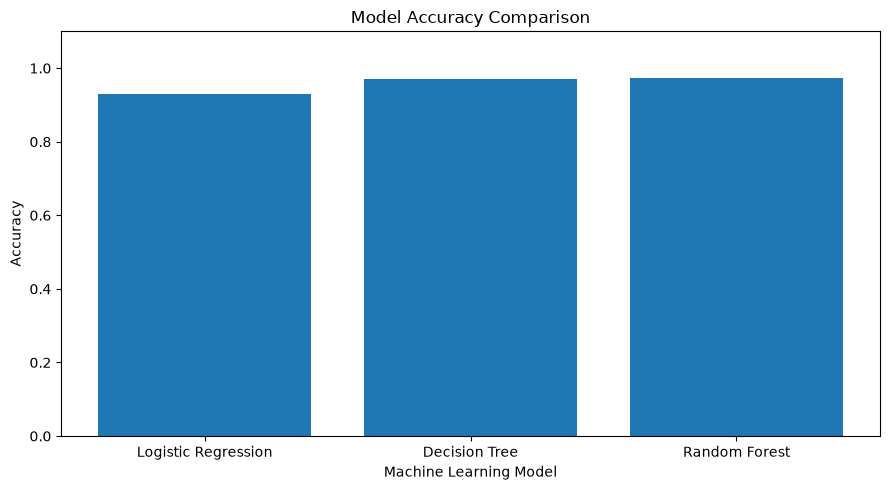

In [ ]:
# imports the necessary libraries for plotting and calculating accuracy
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Creates a list of model names and their corresponding accuracy scores
models = ['Logistic Regression', 'Decision Tree', 'Random Forest']

# Calculates the accuracy of each model's predictions on the test set
accuracy = [
    accuracy_score(y_test, y_pred),
    accuracy_score(y_test, tree_pred),
    accuracy_score(y_test, forest_pred)
]

# Creates a bar chart to visualize the accuracy of each model
plt.figure(figsize=(9, 5))
plt.bar(models, accuracy)

# sets the title, x-axis label, y-axis label, and y-axis limits for the bar chart
plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1.1)

# Displays the bar chart
plt.tight_layout()
plt.show()

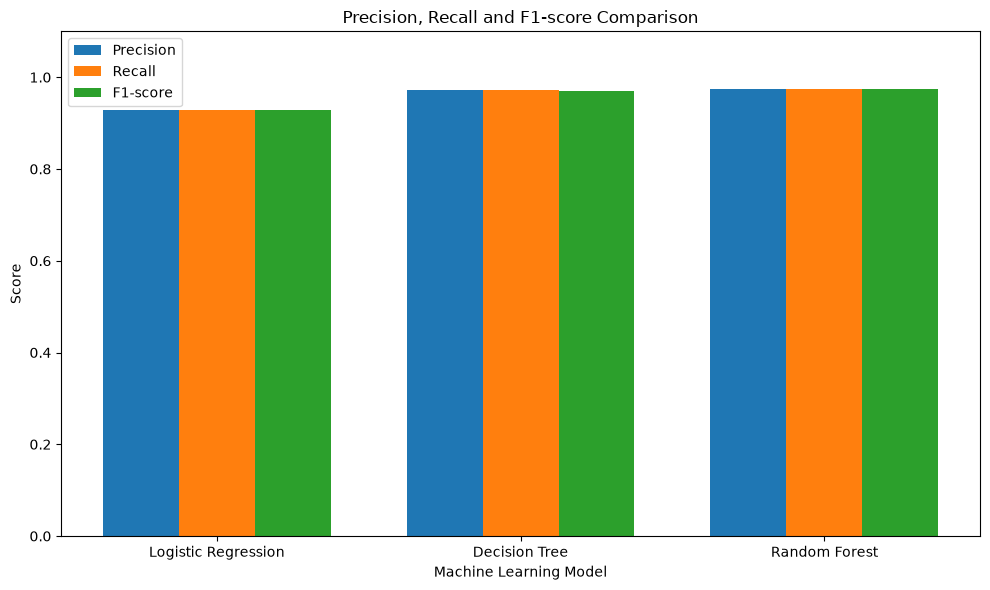

In [ ]:
# Imports the precision_score, recall_score, and f1_score functions from the sklearn.metrics module
from sklearn.metrics import precision_score, recall_score, f1_score

# Creates lists to store the precision, recall, and F1-score for each model
precision = [
    precision_score(y_test, y_pred, average='weighted'),
    precision_score(y_test, tree_pred, average='weighted'),
    precision_score(y_test, forest_pred, average='weighted')
]

# Creates lists to store the recall and F1-score for each model
recall = [
    recall_score(y_test, y_pred, average='weighted'),
    recall_score(y_test, tree_pred, average='weighted'),
    recall_score(y_test, forest_pred, average='weighted')
]

# Creates lists to store the F1-score for each model
f1 = [
    f1_score(y_test, y_pred, average='weighted'),
    f1_score(y_test, tree_pred, average='weighted'),
    f1_score(y_test, forest_pred, average='weighted')
]

# Creates x-axis positions for the bars
x = range(len(models))

# width of the bars in the bar chart
width = 0.25

# figures the size of the bar chart
plt.figure(figsize=(10, 6))

# Plots the precision, recall, and F1-score for each model as separate bars in the bar chart
plt.bar([i - width for i in x], precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar([i + width for i in x], f1, width, label='F1-score')

# sets the title, x-axis label, y-axis label, and y-axis limits for the bar chart
plt.title('Precision, Recall and F1-score Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.xticks(list(x), models)
plt.ylim(0, 1.1)
plt.legend()

# sets the title, x-axis label, y-axis label, and y-axis limits for the bar chart
plt.tight_layout()
plt.show()

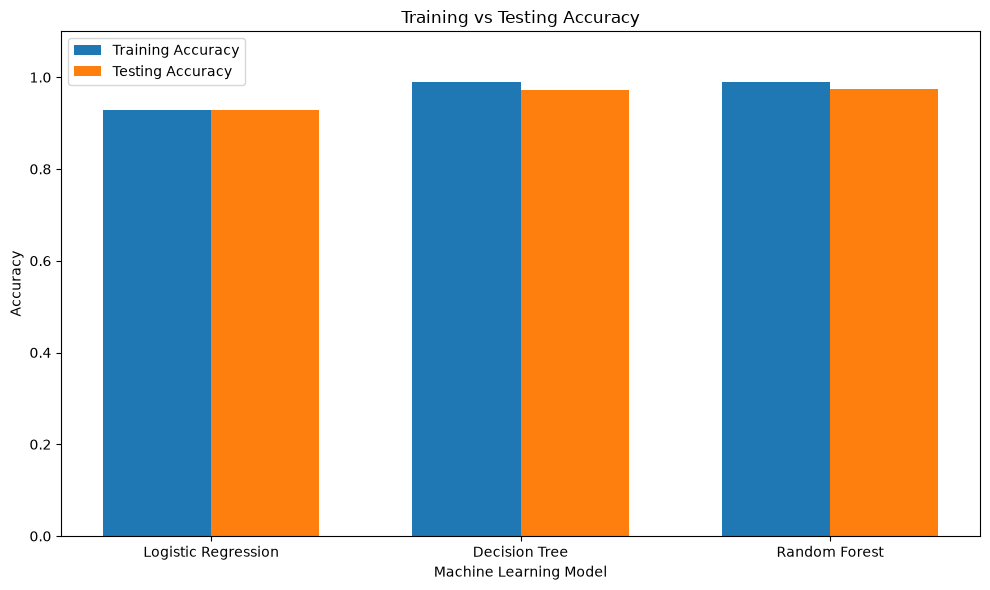

In [ ]:
# Creates lists to store the training and testing accuracy for each model
training_accuracy = [
    accuracy_score(y_train, model.predict(X_train)),
    accuracy_score(y_train, tree_model.predict(X_train)),
    accuracy_score(y_train, forest_model.predict(X_train))
]

# Creates lists to store the testing accuracy for each model
testing_accuracy = [
    accuracy_score(y_test, y_pred),
    accuracy_score(y_test, tree_pred),
    accuracy_score(y_test, forest_pred)
]

# sets the x-axis positions for the bars and the width of the bars in the bar chart
x = range(len(models))
width = 0.35

# figures the size of the bar chart
plt.figure(figsize=(10, 6))

# Plots the training and testing accuracy for each model as separate bars in the bar chart
plt.bar([i - width/2 for i in x], training_accuracy,
        width, label='Training Accuracy')

# Plots the training and testing accuracy for each model as separate bars in the bar chart
plt.bar([i + width/2 for i in x], testing_accuracy,
        width, label='Testing Accuracy')

# sets the title, x-axis label, y-axis label, and y-axis limits for the bar chart
plt.title('Training vs Testing Accuracy')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy')
plt.xticks(list(x), models)
plt.ylim(0, 1.1)
plt.legend()

# sets the title, x-axis label, y-axis label, and y-axis limits for the bar chart
plt.tight_layout()
plt.show()